In [1]:
# Import the necessary libraries and the class
from   climateScenario import climateScenario
import matplotlib.pyplot as plt
import pandas as pd
import copy

In [7]:
# Default scenario historical from 1750 + ssp245 up to 2100
hist = climateScenario( 'historical', ecs = 3, end_year = 2100 )
hist.emissions
hist.integrate()

In [8]:
# Make some spatial calculations based on gmst
boston_location = (42.3601, -71.0589)
model           = 'MPI-ESM1-2-LR'
local_temps = hist.patternScalingTemporal(boston_location, 'tas', model = model)
spatial_map = hist.patternScalingSpatial(2025, 'tas', model = model)

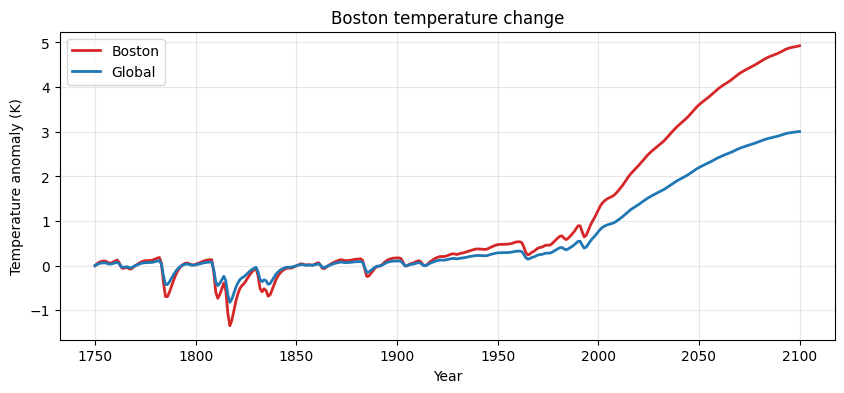

In [5]:
#Boston temperature time series
fig, ax = plt.subplots(figsize=(10, 4))

local_temps.plot(ax=ax, color='tab:red', lw=2)
plt.plot( hist.outdf['GMST'], color='tab:blue', lw=2)
ax.set(xlabel='Year', ylabel='Temperature anomaly (K)', title='Boston temperature change')
ax.grid(alpha=0.3)
ax.legend(['Boston', 'Global'])
plt.show()


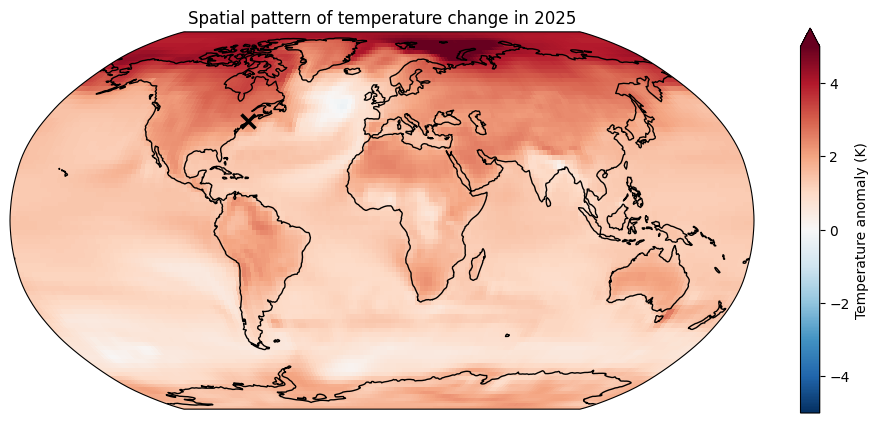

In [9]:
# Plot spatial map and temporal evolution of local temperatures

import cartopy.crs as ccrs

fig, ax = plt.subplots( figsize=(12, 5), subplot_kw={'projection': ccrs.Robinson()} )

spatial_map.plot( ax=ax, transform=ccrs.PlateCarree(), cmap='RdBu_r', vmin=-5, vmax=5, cbar_kwargs={'label': 'Temperature anomaly (K)'} )
ax.coastlines()
ax.set_global()
ax.set_title('Spatial pattern of temperature change in 2025')

# Mark selected location with an X
lat, lon = boston_location
ax.plot( lon, lat,  marker='x', color='black', markersize=10, markeredgewidth=2.5, linestyle='None', transform=ccrs.PlateCarree(), zorder=10 )
plt.show()

In [ ]:
# Custom scenario example (could replace my_custom_ch4_values with EPPA emissions)
newscen              = climateScenario( 'historical', ecs = 3, end_year = 2100 )
my_custom_ch4_values = newscen.emissions.loc[2025:2100, 'ppbCH4'] # could be replaced with emissions from EPPA
newscen.name         = 'Custom CH4 scenario'
newscen.emissions.loc[2025:2100, 'ppbCH4'] = my_custom_ch4_values
newscen.integrate()